# ③ 当年成績による翌年ERA予測

## 研究目的と仮説

当年の投手成績から翌シーズンのERAを予測し、前年ERAの持越しと訓練平均による予測を基準に評価する。FIP、WHIP、K/9、BB/9などを追加し、縮小推定や非線形モデルを用いることで誤差が小さくなるという仮説を設定した。

## 使用データと対象定義

FanGraphsの2018〜2025年の投手シーズン成績を使用する。`IDfg`と連続する年度で1対1に結合し、当年20投球回以上で翌年ERAを観測できる投手を主分析対象とする。名前による結合は行わず、投手IDと年度の重複があれば処理を停止する。

翌年非登板などでERAを観測できない投手は0で補完せず、非観測件数と当年成績を別に確認する。翌年登板する集団に条件付けた評価であり、全投手への適用には生存者バイアスが残る。規定投球回は選択条件に使用しない。

In [1]:
# リポジトリ内の共通処理を読み込む
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / 'src'))
from mlb_portfolio.data import *
from mlb_portfolio.analysis import *

# 集計表の表示範囲を設定する（分析対象の行数・列数は変更しない）
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 35)


## 1. データ品質と対象選択

取得済みデータを読み込み、選択条件による件数変化、要約統計、欠損率と評価期間を確認する。取得ログ・データ定義は[出典と利用条件](../DATA_SOURCES.md)を参照。

In [2]:
# 取得済みキャッシュを優先して2018〜2025年の投手成績を読み込む
raw = pitching_data()
# 投手IDと連続年で当年特徴量・翌年ERAを結合する
pairs = era_pairs(raw)
# 対象件数、欠損率、年度別の翌年ERA観測数を確認する
quality(raw, pairs, 'era')

,rows,stage
0,6736,all_pitcher_seasons
1,3602,year_t_20IP_and_t<=2024
2,3006,observed_next_year


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Throws,3602,2,R,2618,NaN,NaN,NaN,NaN,NaN,NaN,NaN
xMLBAMID,3602.0,NaN,NaN,NaN,603659.732926,67825.128233,112526.0,571710.0,621051.5,660014.5,808967.0
Name,3602,1281,Luis Garcia,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Team,3602,211,- - -,456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,3602.0,NaN,NaN,NaN,2021.073848,2.031982,2018.0,2019.0,2021.0,2023.0,2024.0
Age,3602.0,NaN,NaN,NaN,28.431982,3.641221,19.0,26.0,28.0,31.0,45.0
AgeR,3602,26,27 - 27,412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeasonMin,3602.0,NaN,NaN,NaN,2021.073848,2.031982,2018.0,2019.0,2021.0,2023.0,2024.0
SeasonMax,3602.0,NaN,NaN,NaN,2021.073848,2.031982,2018.0,2019.0,2021.0,2023.0,2024.0
W,3602.0,NaN,NaN,NaN,4.137979,3.695296,0.0,1.0,3.0,6.0,21.0


,size,count,mean
target_year,,,
2019,530,454,4.991187
2020,545,422,5.561666
2021,323,304,4.733798
2022,567,466,4.358483
2023,546,459,4.644734
2024,550,455,4.576665
2025,541,446,4.613171


## 2. 探索的分析と統計的検討

分布・集計・可視化から傾向を確認し、訓練データのみで統計モデルを推定する。係数と区間は探索的な関連として解釈する。

,eligible,returned,absent_next_year
Season,,,
2018,530,454,76
2019,545,422,123
2020,323,304,19
2021,567,466,101
2022,546,459,87
2023,550,455,95
2024,541,446,95


,ERA,IP,Age
target,,,
False,5.082905,50.607550,29.196309
True,4.108687,75.127179,28.280439


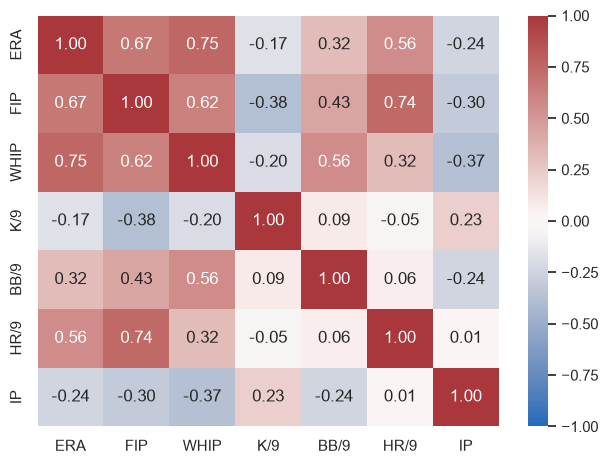

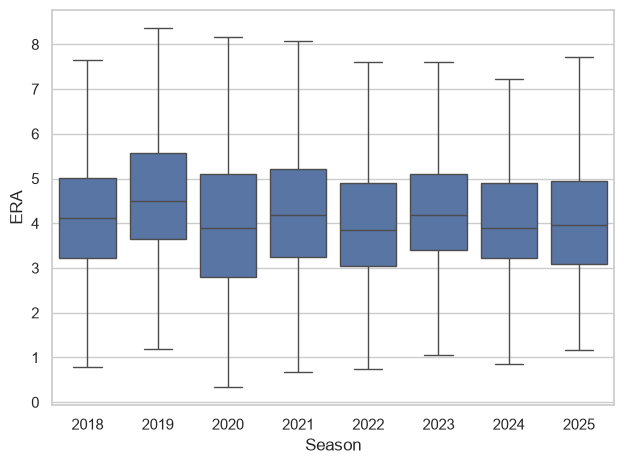

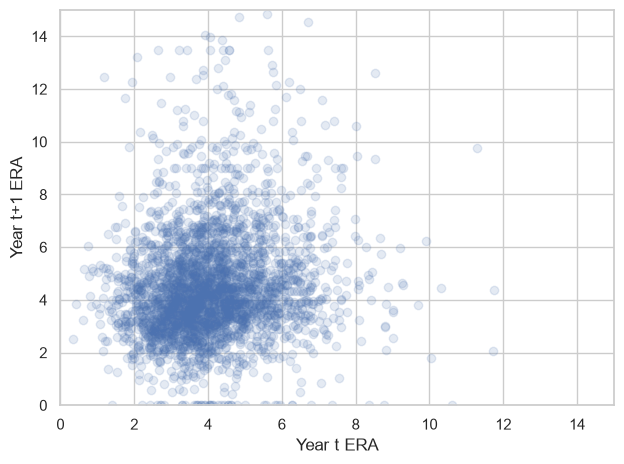

,coefficient,lower95,upper95,p_value
Intercept,4.189214,1.717925,6.660502,0.000892
ERA,0.222953,-0.107235,0.553142,0.185693
FIP,0.238002,-0.105547,0.581551,0.174523
WHIP,0.086165,-1.932897,2.105227,0.933340
K9,-0.119469,-0.213489,-0.025449,0.012757
BB9,0.131680,-0.149066,0.412427,0.357941
Age,-0.024648,-0.073682,0.024385,0.324500


In [3]:
# 翌年非観測、指標間相関、年次変動、訓練内の関連を確認する
# 戻り値は翌年ERAが観測できる投手年の表とする
df = era_eda(raw, pairs)

## 3. モデル比較と評価方法

目的年2019〜2022年を訓練、2023年を検証、2024〜2025年を固定テストとする。年tの成績だけで年t+1のERAを予測し、翌年の投球回や役割は特徴量に含めない。

訓練平均、前年ERA持越し、ERAのみ・特徴量追加のRidge回帰、設定の異なるRandom Forestを検証RMSEで比較する。追加特徴はFIP、WHIP、K/9、BB/9、HR/9、年齢、投球回、先発数、登板数。IPの小数表記を実際の投球回に変換し、前処理を訓練データ内で学習する。乱数は42に固定する。

固定テストでは選択モデルと固定ベースラインのMAE・RMSEを評価する。投手単位の対応付きブートストラップ400回でRMSE差の95%区間を算出し、当年の投球回・役割別の誤差は事後診断として扱う。

,task,model,split,n_train,n_eval,features,MAE,RMSE
0,era,baseline_mean,validation,1646,459,ERA,1.584270,2.671185
1,era,ridge_basic,validation,1646,459,ERA,1.527515,2.644427
2,era,ridge_extended,validation,1646,459,"ERA,FIP,WHIP,K/9,BB/9,HR/9,Age,IP_innings,GS,G",1.474008,2.599761
3,era,rf_leaf20,validation,1646,459,"ERA,FIP,WHIP,K/9,BB/9,HR/9,Age,IP_innings,GS,G",1.469903,2.603315
4,era,rf_leaf50,validation,1646,459,"ERA,FIP,WHIP,K/9,BB/9,HR/9,Age,IP_innings,GS,G",1.442302,2.573442
5,era,previous_ERA,validation,1646,459,NaN,1.745893,2.917441
6,era,rf_leaf50,test,1646,901,NaN,1.736266,3.452025
7,era,baseline_mean,test,1646,901,NaN,1.774762,3.502707
8,era,previous_ERA,test,1646,901,NaN,1.853773,3.653176


Validation-selected: rf_leaf50


,comparison,metric,lower95,upper95,clusters,bootstrap
0,rf_leaf50 minus previous_ERA,RMSE,-0.314393,-0.139714,595,400


,comparison,metric,lower95,upper95,clusters,bootstrap
0,rf_leaf50 minus training_mean,RMSE,-0.092342,0.002095,595,400


,IDfg,Name,Season,target_year,IP,GS,ERA,target,prediction,error,abs_error
4777,13420,Matt Koch,2023,2024,38.2,1.0,5.120690,81.000084,5.884445,-75.115639,75.115639
4833,21205,Connor Brogdon,2023,2024,29.0,1.0,4.034484,24.000009,5.360687,-18.639321,18.639321
5366,18769,Cody Poteet,2024,2025,24.1,4.0,2.219178,16.875004,4.722606,-12.152398,12.152398
5122,10123,Kyle Gibson,2024,2025,169.2,30.0,4.243615,16.783786,4.757282,-12.026503,12.026503
5556,25862,Noah Davis,2024,2025,20.1,0.0,5.754099,18.000002,6.211066,-11.788936,11.788936
4482,25551,Isaiah Campbell,2023,2024,28.2,0.0,2.825582,16.200002,4.494576,-11.705425,11.705425
5142,14857,Joe Mantiply,2024,2025,59.2,2.0,3.921789,15.827589,4.201195,-11.626394,11.626394
4978,26128,Amos Willingham,2023,2024,24.1,0.0,6.657535,18.000000,6.720173,-11.279827,11.279827
4424,21238,Allan Winans,2023,2024,32.1,6.0,5.288660,15.260871,4.866652,-10.394219,10.394219
5231,22533,Michel Otanez,2024,2025,34.0,0.0,3.441177,13.500003,4.238936,-9.261067,9.261067


n       MAE      RMSE
target_year role                               
2024        10+ starts  168  1.290527  1.758167
            <10 starts  287  2.123947  5.187484
2025        10+ starts  160  1.260620  1.767027
            <10 starts  286  1.875157  2.640913

,n,MAE,RMSE
ip_band,,,
"(19, 50]",277,2.497897,5.538358
"(50, 100]",390,1.505288,1.986071
"(100, 150]",109,1.272089,1.567020
"(150, 300]",125,1.173903,1.863784


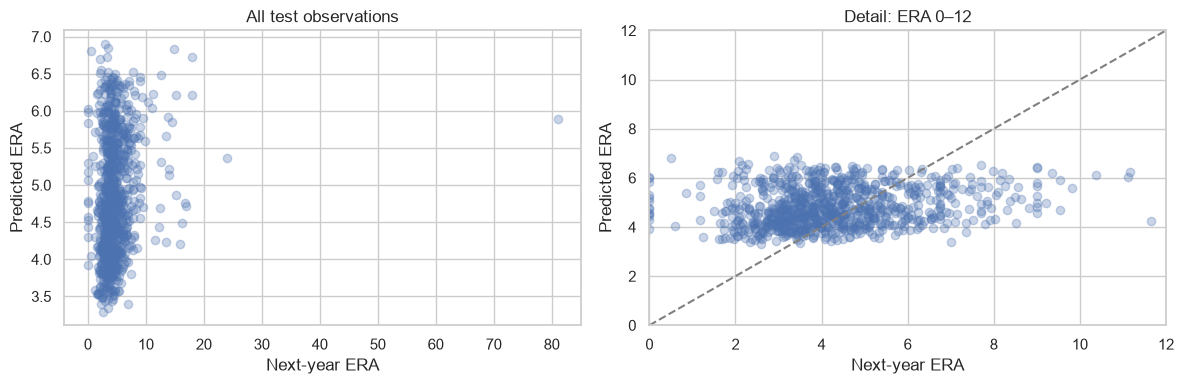

In [4]:
# 検証データでモデルを固定し、テスト指標・図・実験CSVを出力する
results = evaluate(df, 'era')

## 4. 結果の解釈と限界

検証RMSEはERAのみのRidgeで2.644、特徴量追加Ridgeで2.600、選択したRandom Forest（最小葉50）で2.573だった。固定テストでは選択モデルのMAEが1.736、RMSEが3.452で、前年ERA持越しのRMSE3.653を下回った。

一方、訓練平均のテストRMSEは3.503であり、平均比のRMSE差の95%区間は−0.092〜+0.002と0を含む。平均予測に対する追加価値は明確ではない。翌年1アウト・3自責点によるERA81の観測も含み、少数登板による極端値がRMSEに影響した。

当年20IP以上の3,602件中、翌年ERA非観測596件を除外した3,006投手年が対象である。翌年登板に条件付けた生存者バイアス、当年IP閾値、2020年短縮シーズンの影響が残る。故障や役割変更の予測、年次ローリング検証は未実施。詳細は[分析レポート](../reports/REPORT.md)に記載する。